In [13]:
import numpy as np
import polars as pl

import matplotlib.pyplot as plt

from ternary_diagram import TernaryDiagram

from skbio.stats.composition import clr
from scipy.spatial.distance import euclidean


def aitchison(x, y):
    return euclidean(clr(x), clr(y))

## Scale invariance
A funciton is scale invariance if $f(x)$ is equal to $f(\lambda x)$ with $\lambda$ as a constant. A common function that is not scale invariance is the euclidian distance.

In [14]:
vec_a = np.array([0.3, 0.2, 0.5])
vec_b = np.array([0.35, 0.22, 0.43])
scale_a = vec_a*6
scale_b = vec_b*6

print("$d_e()$ ", euclidean(vec_a, vec_b))
print(euclidean(scale_a, scale_b))

print("$d_a()$ ", aitchison(vec_a, vec_b))
print(aitchison(scale_a, scale_b))

$d_e()$  0.08831760866327847
0.5299056519796707
$d_a()$  0.22880309620201503
0.22880309620201497


## Subcompostional coherence
Subcompositional coherence means that the distance between two subcompostions should be less or the same as the distance between the original compositions.

In [15]:
# remove element two from vector a and vector b
a_sub = np.array([0.3/0.8, 0.5/0.8])
b_sub = np.array([0.35/0.78, 0.43/0.78])
print(a_sub)
print(b_sub)
print("$d_e(a_sub, b_sub)$ ", euclidean(a_sub, b_sub))
print("$d_a(a_sub, b_sub)$ ", aitchison(a_sub, b_sub))

[0.375 0.625]
[0.44871795 0.55128205]
$d_e(a_sub, b_sub)$  0.10425292286724745
$d_a(a_sub, b_sub)$  0.2156488791198458


## Permutational invariance
The idear with this example is to show that with two molecules, A and B, in the ratio 1:1 and one molecules is doubled the change should be the same either if it is A or B that are doubled.
A and B are just names, so 1A:2B should be the same as 2A:1B. In linear space it will be 1/2=0.5 or 2/1=2. When consider it on log-space it will be ln(1/2)=-0.693147 or ln(2/1)=0.693147.

In [16]:
df = pl.DataFrame(
    {
        "A": [1, 1, 1, 1, 1, 2, 3, 4, 5],
        "B": [5, 4, 3, 2, 1, 1, 1, 1, 1],
    }
)

df.insert_column(column=(pl.col("A")/pl.col("B")).alias("ratio"), index=2)
df.insert_column(column=(pl.col("ratio")-1).alias("lin_change"), index=3)
df.insert_column(column=(abs(pl.col("ratio")-1)).alias("abs_lin_change"), index=4)
df.insert_column(column=(np.log(pl.col("A")/pl.col("B"))).alias("log"), index=5)
df.insert_column(column=(pl.col("log")-0).alias("log_change"), index=6)
df.insert_column(column=(abs(pl.col("log"))).alias("abs_log_change"), index=7)
df.insert_column(column=(pl.col("A")-pl.col("B")).alias("x_axis"), index=8)
df.insert_column(column=(pl.col("A")+pl.col("B")).alias("sum"),index=9)
print(df)

shape: (9, 10)
┌─────┬─────┬──────────┬────────────┬───┬────────────┬────────────────┬────────┬─────┐
│ A   ┆ B   ┆ ratio    ┆ lin_change ┆ … ┆ log_change ┆ abs_log_change ┆ x_axis ┆ sum │
│ --- ┆ --- ┆ ---      ┆ ---        ┆   ┆ ---        ┆ ---            ┆ ---    ┆ --- │
│ i64 ┆ i64 ┆ f64      ┆ f64        ┆   ┆ f64        ┆ f64            ┆ i64    ┆ i64 │
╞═════╪═════╪══════════╪════════════╪═══╪════════════╪════════════════╪════════╪═════╡
│ 1   ┆ 5   ┆ 0.2      ┆ -0.8       ┆ … ┆ -1.609438  ┆ 1.609438       ┆ -4     ┆ 6   │
│ 1   ┆ 4   ┆ 0.25     ┆ -0.75      ┆ … ┆ -1.386294  ┆ 1.386294       ┆ -3     ┆ 5   │
│ 1   ┆ 3   ┆ 0.333333 ┆ -0.666667  ┆ … ┆ -1.098612  ┆ 1.098612       ┆ -2     ┆ 4   │
│ 1   ┆ 2   ┆ 0.5      ┆ -0.5       ┆ … ┆ -0.693147  ┆ 0.693147       ┆ -1     ┆ 3   │
│ 1   ┆ 1   ┆ 1.0      ┆ 0.0        ┆ … ┆ 0.0        ┆ 0.0            ┆ 0      ┆ 2   │
│ 2   ┆ 1   ┆ 2.0      ┆ 1.0        ┆ … ┆ 0.693147   ┆ 0.693147       ┆ 1      ┆ 3   │
│ 3   ┆ 1   ┆ 3.0      ┆ 2.0

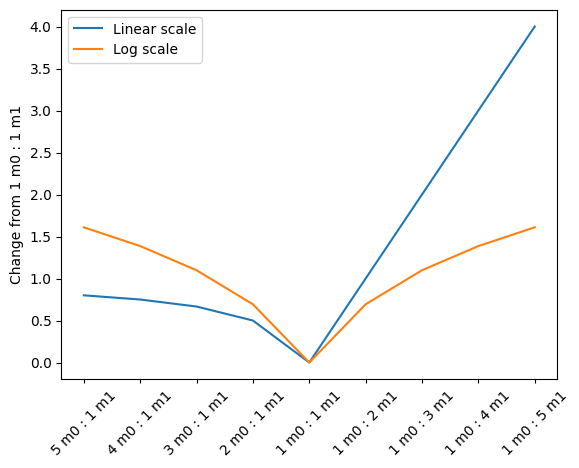

In [17]:
fig_change, ax_change = plt.subplots()
ax_change.plot(df["x_axis"].to_numpy(), df["abs_lin_change"].to_numpy(), label='Linear scale')
ax_change.plot(df["x_axis"].to_numpy(), df["abs_log_change"].to_numpy(), label='Log scale')
# ax_change.set_xticks(df["x_axis"], labels=("add 4 part\n unlabelled","add 3 part\n  unlabelled", "add 2 part\n  unlabelled","add 1 part\n  unlabelled","same", "add 1 part\n  labelled", "add 2 part\n  labelled", "add 3 part\n  labelled","add 4 part\n  labelled"))
# ax_change.set_xticks(df["x_axis"], labels=("5 m0\n 1 m1","4 m0\n 1 m1", "3 m0\n 1 m1","2 m0\n 1 m1","1 m0\n 1 m1", "1 m0\n 2 m1", "1 m0\n 3 m1", "1 m0\n 4 m1","1 m0\n 5 m1"))
ax_change.set_xticks(df["x_axis"], labels=("5 m0 : 1 m1","4 m0 : 1 m1", "3 m0 : 1 m1","2 m0 : 1 m1","1 m0 : 1 m1", "1 m0 : 2 m1", "1 m0 : 3 m1", "1 m0 : 4 m1","1 m0 : 5 m1"))
ax_change.tick_params(axis="x", length=3, labelrotation= 45)
ax_change.set_ylabel("Change from 1 m0 : 1 m1")
ax_change.legend()
plt.show()

## Comparison of euclidean distance and aitchison distance
Example on how the euclidean distance and the aitchison distance changes when the compositions changes with steps of 0.05 

In [18]:
df_two_molecules = pl.DataFrame(    
    {
        "m0": [0.95, 0.9, 0.85, 0.80, 0.75, 0.7, 0.65, 0.6, 0.55, 0.50, 0.45, 0.40],
        "m1": [0.05, 0.1, 0.15, 0.20, 0.25, 0.3, 0.35, 0.4, 0.45, 0.50, 0.55, 0.60],
    }
)

In [19]:
def add_dists(df = pl.DataFrame) -> pl.DataFrame:
    eucl_dist = [euclidean(df[h].to_numpy()[0], df[h+1].to_numpy()[0]) for h in range(len(df)-1)]
    aitc_dist = [aitchison(df[h].to_numpy()[0], df[h+1].to_numpy()[0]) for h in range(len(df)-1)]
    eucl_dist.append(None)
    aitc_dist.append(None)
    df_dist = pl.DataFrame(
        {
            "eucl_dist": eucl_dist,
            "aitc_dist": aitc_dist,
        }
    )
    return pl.concat([df, df_dist], how="horizontal")

df_new01 = add_dists(df_two_molecules)
print(df_new01)

shape: (12, 4)
┌──────┬──────┬───────────┬───────────┐
│ m0   ┆ m1   ┆ eucl_dist ┆ aitc_dist │
│ ---  ┆ ---  ┆ ---       ┆ ---       │
│ f64  ┆ f64  ┆ f64       ┆ f64       │
╞══════╪══════╪═══════════╪═══════════╡
│ 0.95 ┆ 0.05 ┆ 0.070711  ┆ 0.52836   │
│ 0.9  ┆ 0.1  ┆ 0.070711  ┆ 0.327124  │
│ 0.85 ┆ 0.15 ┆ 0.070711  ┆ 0.24629   │
│ 0.8  ┆ 0.2  ┆ 0.070711  ┆ 0.203422  │
│ 0.75 ┆ 0.25 ┆ 0.070711  ┆ 0.177706  │
│ …    ┆ …    ┆ …         ┆ …         │
│ 0.6  ┆ 0.4  ┆ 0.070711  ┆ 0.144812  │
│ 0.55 ┆ 0.45 ┆ 0.070711  ┆ 0.141896  │
│ 0.5  ┆ 0.5  ┆ 0.070711  ┆ 0.141896  │
│ 0.45 ┆ 0.55 ┆ 0.070711  ┆ 0.144812  │
│ 0.4  ┆ 0.6  ┆ null      ┆ null      │
└──────┴──────┴───────────┴───────────┘


c:\Users\afjsl\Documents\cmfa\.venv\Lib\site-packages\ternary\plotting.py:148: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(xs, ys, vmin=vmin, vmax=vmax, **kwargs)


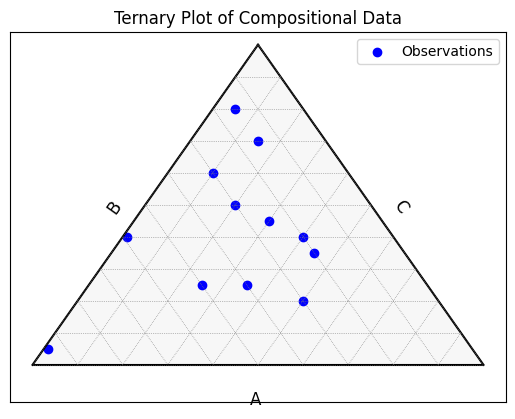

In [ ]:
import ternary
import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    [0.20, 0.50, 0.30],
    [0.10, 0.60, 0.30],
    [0.35, 0.25, 0.40],
    [0.40, 0.40, 0.20],
    [0.15, 0.70, 0.15],
    [0.25, 0.25, 0.50],
    [0.05, 0.80, 0.15],
    [0.30, 0.45, 0.25],
    [0.50, 0.20, 0.30],
    [0.45, 0.35, 0.20],
    [0.01, 0.40, 0.59],
    [0.01, 0.05, 0.94],
])
figure, tax = ternary.figure(scale=1)
tax.scatter(data, marker='o', color='blue', label="Observations")

tax.boundary()
tax.gridlines(multiple=0.1, color="gray")

# Set axis labels
tax.left_axis_label("B", fontsize=12)
tax.right_axis_label("C", fontsize=12)
tax.bottom_axis_label("A", fontsize=12)

# Title and legend
tax.set_title("Ternary Plot of Compositional Data")
tax.legend()

# Remove default matplotlib axes
tax.clear_matplotlib_ticks()

plt.show()

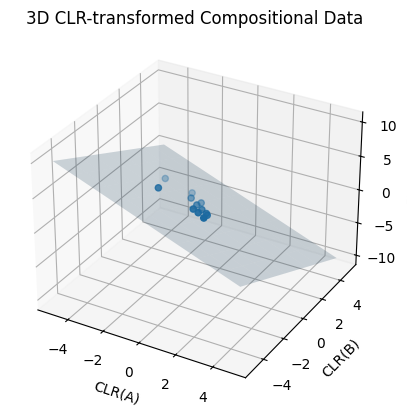

In [16]:
# CLR transformation
def clr(x):
    g = np.exp(np.mean(np.log(x)))
    return np.log(x / g)

clr_data = np.array([clr(row) for row in data])

# 3D Plot
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(clr_data[:, 0], clr_data[:, 1], clr_data[:, 2])

ax.set_xlabel("CLR(A)")
ax.set_ylabel("CLR(B)")
ax.set_zlabel("CLR(C)")
ax.set_title("3D CLR-transformed Compositional Data")
id="plane"
xx, yy = np.meshgrid(np.linspace(-5,5,10), np.linspace(-5,5,10))
zz = -xx - yy  # because x + y + z = 0

ax.plot_surface(xx, yy, zz, alpha=0.2)
plt.show()

In [ ]:
import plotly.graph_objects as go


# Create interactive 3D scatter plot
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=clr_data[:, 0],
    y=clr_data[:, 1],
    z=clr_data[:, 2],
    mode='markers+text',
    text=[f"P{i+1}" for i in range(len(clr_data))],
    textposition="top center",
    marker=dict(size=5)
))
xx, yy = np.meshgrid(np.linspace(-1.5,0.5,10), np.linspace(-0.5,1.5,10))
zz = -xx - yy

fig.add_trace(go.Surface(
    x=xx, y=yy, z=zz,
    opacity=0.2,
    showscale=False
))

# Axis labels
fig.update_layout(
    title="Interactive 3D CLR Plot",
    scene=dict(
        xaxis_title="CLR(A)",
        yaxis_title="CLR(B)",
        zaxis_title="CLR(C)"
    )
)

fig.show()